# 03 - Estensione ad altri pazienti virtuali (adult#001, #002, #003)

**Obiettivo.** Ripetere il confronto tra PID standard e controllore IOB-constrained su altri pazienti virtuali, con **condizioni identiche** a quelle del notebook 02 (stessi guadagni e stessi parametri, pasto non annunciato da 60 g alle 12:00, stesso seme del rumore). I parametri dei controllori non vengono ritarati sul singolo paziente: il tetto IOB si scala solo con il fabbisogno basale del paziente.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
import aid_sim as A, notebook_utils as U
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 110)
SEED = 1                      # seme del rumore del sensore (uguale per tutti i controllori)
PID  = {}                     # PID di riferimento: parametri di default di AIDController
PROP = dict(use_iob=True, use_plgs=True)   # controllore proposto: stesso PID + tetto IOB + PLGS
print("Versioni delle librerie usate:"); display(U.library_versions())

Versioni delle librerie usate:


,Pacchetto,Versione
0,Python,3.12.3
1,simglucose,0.2.11
2,numpy,2.4.4
3,scipy,1.17.1
4,pandas,3.0.2
5,matplotlib,3.10.8


## 1. Configurazione
### 1.1 Pazienti (parametri di simglucose)

In [2]:
import os, simglucose
from simglucose.patient.t1dpatient import T1DPatient
PAZ = ['adult#001', 'adult#002', 'adult#003']
q = pd.read_csv(os.path.join(os.path.dirname(simglucose.__file__), 'params', 'Quest.csv')).set_index('Name')
rows = []
for p in PAZ:
    ic = U.initial_conditions(p, SEED)
    rows.append({'Paziente': p, 'BW [kg]': round(ic['BW'], 1), 'Gb [mg/dL]': round(ic['Gb'], 1), 'u_b [U/h]': round(ic['ub']*60, 2),
                 'CR [g/U]': q.loc[p, 'CR'], 'CF [mg/dL/U]': q.loc[p, 'CF'], 'TDI [U/die]': q.loc[p, 'TDI'],
                 'BG iniziale [mg/dL]': round(ic['bg0'], 1), 'CGM iniziale [mg/dL]': round(ic['cgm0'], 1)})
display(pd.DataFrame(rows))

,Paziente,BW [kg],Gb [mg/dL],u_b [U/h],CR [g/U],CF [mg/dL/U],TDI [U/die],BG iniziale [mg/dL],CGM iniziale [mg/dL]
0,adult#001,102.3,138.6,1.27,10,8.773107,50.416652,138.6,152.0
1,adult#002,111.1,136.4,1.37,8,9.212763,57.868777,136.5,149.9
2,adult#003,81.6,147.1,1.43,9,17.934552,56.429719,147.1,160.5


### 1.2 Scenario e controllori
Durata 16 h, passo 3 min (320 passi), inizio 08:00, pasto non annunciato di 60 g alle 12:00, seme 1. Parametri e unità dei controllori: stessi del notebook 02.

In [3]:
display(U.scenario_table('adult#001', 60.0, SEED).iloc[6:])
ub1 = U.initial_conditions('adult#001', SEED)['ub']
print("PID + IOB + PLGS (il tetto IOB cambia con il basale del paziente: 1.5 x basale orario)"); display(U.controller_table(PROP, ub1))

,Voce,Valore,Unita'
6,Seme casuale sensore (seed),1,-
7,Inizio simulazione,08:00,ora solare
8,Durata simulazione,16.0,h
9,Passo di campionamento dt,3.0,min
10,Numero complessivo di passi,320,-
11,Glicemia plasmatica iniziale (t=0),138.6,mg/dL
12,Misura CGM iniziale (t=0),152.0,mg/dL
13,"Stati iniziali IOB (S1, S2)","0.0, 0.0",U
14,Orario somministrazione pasto,12:00 (offset t = 4 h),ora solare
15,Carico di carboidrati (CHO),60.0,g


PID + IOB + PLGS (il tetto IOB cambia con il basale del paziente: 1.5 x basale orario)


,Parametro,Valore,Unita',Significato
0,target,120.0,mg/dL,Glicemia obiettivo del regolatore
1,kp,0.0001,U/min per mg/dL,Guadagno proporzionale
2,ki,0.000005,U/min per (mg/dL*min),Guadagno integrale
3,kd,0.002,U/min per (mg/dL/min),Guadagno derivativo sulla pendenza CGM (segno positivo)
4,i_min,-2000.0,mg*min/dL,Limite inferiore anti-windup (clamping)
5,i_max,10000.0,mg*min/dL,Limite superiore anti-windup (clamping)
6,use_iob,True,-,Attiva il vincolo dinamico sull'insulina attiva (IOB)
7,iob_alpha,1.5,adimensionale,Fattore di scala: tetto IOB = iob_alpha * basale orario
8,tau_s,50.0,min,Costante di tempo dei compartimenti sottocutanei IOB
9,use_plgs,True,-,Attiva la sospensione predittiva dell'infusione (PLGS)


## 2. Verifica nominale a digiuno e pasto da 60 g

In [4]:
R = {(p, c, n): A.simulate(p, c, kw, seed=SEED)[0] for p in PAZ for c in [0.0, 60.0] for n, kw in [('PID', PID), ('PID+IOB+PLGS', PROP)]}
print(len(R), 'simulazioni completate')

12 simulazioni completate


## 3. Grafici (pasto da 60 g): glicemia e IOB per paziente

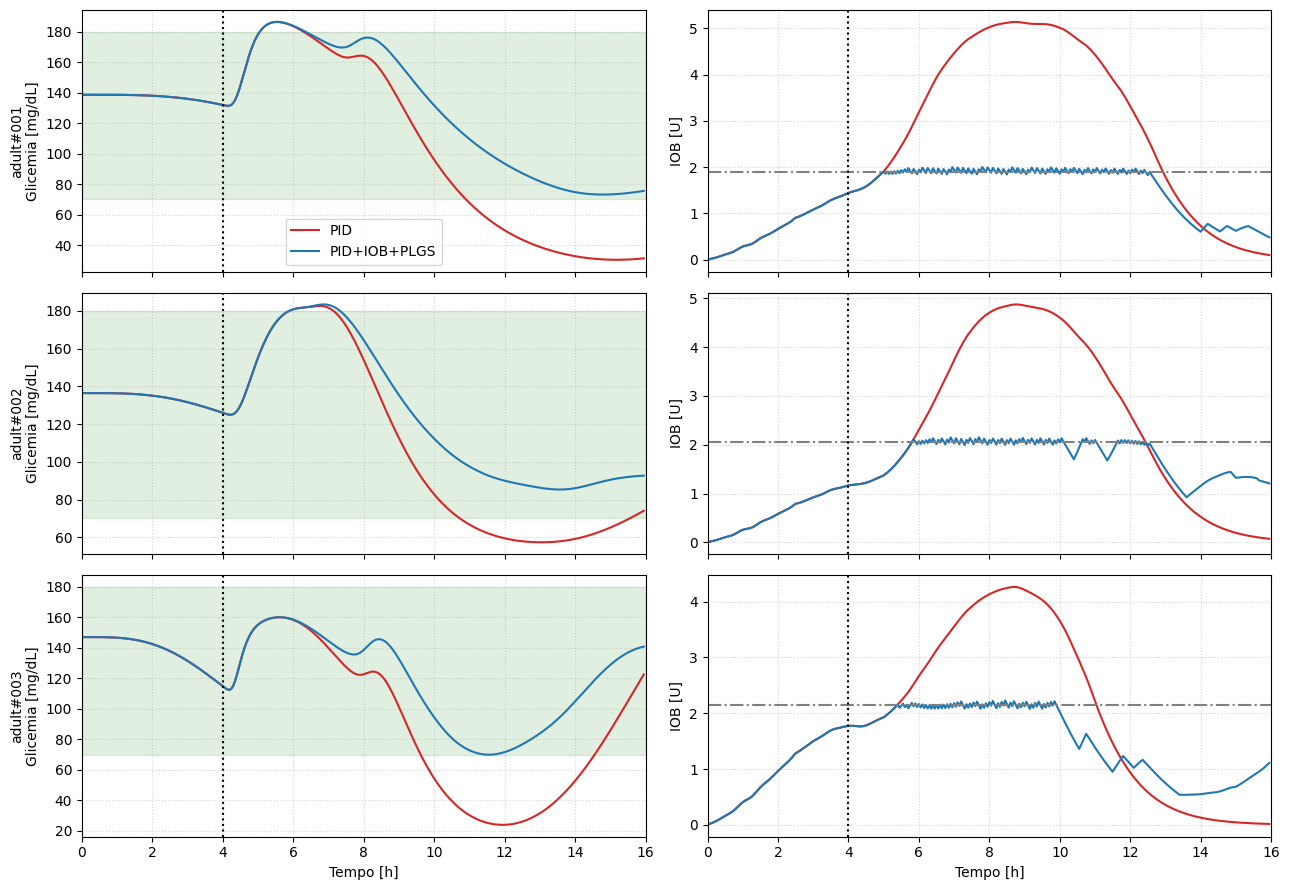

In [5]:
fig, ax = plt.subplots(3, 2, figsize=(13, 9), sharex=True)
for i, p in enumerate(PAZ):
    ub_p = U.initial_conditions(p, SEED)['ub']
    for n, col in [('PID', 'tab:red'), ('PID+IOB+PLGS', 'tab:blue')]:
        d = R[(p, 60.0, n)]; ax[i, 0].plot(d.t_h, d.BG, color=col, label=n); ax[i, 1].plot(d.t_h, d.IOB, color=col)
    ax[i, 1].axhline(1.5*ub_p*60, color='gray', ls='-.')
    ax[i, 0].axhspan(70, 180, color='green', alpha=.12); ax[i, 0].set_ylabel(f'{p}\nGlicemia [mg/dL]'); ax[i, 1].set_ylabel('IOB [U]')
    for j in range(2): ax[i, j].axvline(A.MEAL_OFFSET_H, color='k', ls=':'); ax[i, j].grid(ls=':', alpha=.5)
ax[0, 0].legend(); ax[2, 0].set_xlabel('Tempo [h]'); ax[2, 1].set_xlabel('Tempo [h]'); ax[2, 0].set_xlim(0, 16); plt.tight_layout(); plt.show()

## 4. Indicatori clinici

In [6]:
rows = []
for (p, c, n), d in R.items():
    m = A.metrics(d); rows.append({'Paziente': p, 'CHO [g]': int(c), 'Controllore': n, **{k: round(float(v), 1) for k, v in m.items()}})
T = pd.DataFrame(rows).sort_values(['CHO [g]', 'Paziente', 'Controllore'], ascending=[True, True, False]).reset_index(drop=True)
print("A digiuno (0 g):"); display(T[T['CHO [g]'] == 0].drop(columns='CHO [g]').reset_index(drop=True))
print("Pasto non annunciato (60 g):"); display(T[T['CHO [g]'] == 60].drop(columns='CHO [g]').reset_index(drop=True))

A digiuno (0 g):


,Paziente,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,picco,nadir
0,adult#001,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,138.6,92.4
1,adult#001,PID,100.0,0.0,0.0,0.0,0.0,0.0,138.6,85.2
2,adult#002,PID+IOB+PLGS,100.0,0.0,0.0,0.0,0.0,0.0,137.8,103.5
3,adult#002,PID,100.0,0.0,0.0,0.0,0.0,0.0,139.5,102.7
4,adult#003,PID+IOB+PLGS,87.5,12.5,0.0,0.0,0.0,0.0,196.2,79.2
5,adult#003,PID,100.0,0.0,0.0,0.0,0.0,0.0,178.9,77.8


Pasto non annunciato (60 g):


,Paziente,Controllore,TIR,TAR,TAR>250,TBR,TBR<54,TBR_tardivo,picco,nadir
0,adult#001,PID+IOB+PLGS,92.2,7.8,0.0,0.0,0.0,0.0,186.3,73.1
1,adult#001,PID,60.6,7.5,0.0,31.9,26.6,56.7,186.3,30.4
2,adult#002,PID+IOB+PLGS,90.9,9.1,0.0,0.0,0.0,0.0,183.5,85.3
3,adult#002,PID,61.9,7.8,0.0,30.3,0.0,53.9,182.7,57.3
4,adult#003,PID+IOB+PLGS,99.1,0.0,0.0,0.9,0.0,1.7,160.1,69.9
5,adult#003,PID,69.1,0.0,0.0,30.9,25.0,55.0,160.1,24.0


## 5. Lettura dei risultati (calcolata dalla tabella)

In [7]:
for p in PAZ:
    a = T[(T.Paziente == p) & (T['CHO [g]'] == 60) & (T.Controllore == 'PID')].iloc[0]; b = T[(T.Paziente == p) & (T['CHO [g]'] == 60) & (T.Controllore == 'PID+IOB+PLGS')].iloc[0]
    f = T[(T.Paziente == p) & (T['CHO [g]'] == 0) & (T.Controllore == 'PID+IOB+PLGS')].iloc[0]
    print(f"{p}: TBR {a['TBR']:.1f} -> {b['TBR']:.1f} % | TIR {a['TIR']:.1f} -> {b['TIR']:.1f} % | picco {a['picco']:.0f} -> {b['picco']:.0f} mg/dL | a digiuno il proposto ha TIR {f['TIR']:.1f} %")

adult#001: TBR 31.9 -> 0.0 % | TIR 60.6 -> 92.2 % | picco 186 -> 186 mg/dL | a digiuno il proposto ha TIR 100.0 %
adult#002: TBR 30.3 -> 0.0 % | TIR 61.9 -> 90.9 % | picco 183 -> 184 mg/dL | a digiuno il proposto ha TIR 100.0 %
adult#003: TBR 30.9 -> 0.9 % | TIR 69.1 -> 99.1 % | picco 160 -> 160 mg/dL | a digiuno il proposto ha TIR 87.5 %


**Limiti.** Guadagni e tetto IOB non sono ritarati sul singolo paziente e non sono stati ottimizzati: i risultati mostrano il comportamento con parametri fissi, non il miglior risultato ottenibile per ciascun soggetto.